# 01 · Graphs, Molecules, and the BBBP Problem

**Graph Neural Networks for Medicine — Lesson 1 of 5**

This series builds a GNN for a real medical task **twice**:

| Track | Notebooks | Goal |
|-------|-----------|------|
| **From scratch** | 01 → 02 → 03 | Understand *every* operation — message passing, pooling, batching — with nothing but PyTorch tensors. |
| **With libraries** | 04 → 05 | Rebuild the same model with **PyTorch Geometric**, the library people actually use, and reach advanced architectures. |

**The task (all 5 notebooks):** given a drug molecule, predict whether it crosses the **blood–brain barrier (BBB)** — a core question in CNS drug discovery. This is the **BBBP** benchmark from MoleculeNet (~2,000 molecules).

This first notebook has no neural network at all. It answers one question: **how do you turn a molecule into something a neural network can read?**

## 1. What is a graph?

A graph is just **things** (nodes/vertices) and **connections** between them (edges).

- **Node** → an entity. Here: an *atom*.
- **Edge** → a relationship. Here: a *chemical bond*.
- **Adjacency matrix `A`** → an N×N table where `A[i,j] = 1` if node *i* connects to node *j*.
- **Node feature matrix `X`** → an N×F table: one row of numbers per node describing it.

Almost everything in medicine is naturally a graph: molecules (atoms–bonds), patients linked by similarity, proteins (residues in contact), knowledge graphs of drugs↔diseases. GNNs are the tool for learning on all of them.

In [1]:
import numpy as np

# A tiny graph by hand: 4 nodes in a square, plus one diagonal.
#   0 --- 1
#   |   / |
#   3 --- 2
A = np.array([
    [0,1,0,1],
    [1,0,1,1],
    [0,1,0,1],
    [1,1,1,0],
], dtype=float)

degree = A.sum(axis=1)          # how many neighbours each node has
print("Adjacency matrix:\n", A)
print("Degrees:", degree)       # node 1 and 3 have degree 3
print("Symmetric (undirected)?", np.allclose(A, A.T))

Adjacency matrix:
 [[0. 1. 0. 1.]
 [1. 0. 1. 1.]
 [0. 1. 0. 1.]
 [1. 1. 1. 0.]]
Degrees: [2. 3. 2. 3.]
Symmetric (undirected)? True


### The one idea behind every GNN

A node's meaning comes from **its neighbours**. A carbon atom bonded to three oxygens behaves very differently from a carbon bonded to three other carbons. So the fundamental GNN operation is:

> **look at your neighbours, aggregate their feature vectors, and update your own.**

Multiplying features by the adjacency matrix does exactly this "gather from neighbours" step. We'll make that precise in Notebook 02. For now, notice the mechanism already exists in `A`:

In [2]:
# Give each node a 2-number feature. "A @ X" sums each node's neighbours' features.
X = np.array([[1,0],[0,1],[1,1],[2,0]], dtype=float)
neighbour_sum = A @ X
print("Each node's own features:\n", X)
print("\nSum of each node's NEIGHBOURS' features (A @ X):\n", neighbour_sum)
# Row 1 = features of nodes 0,2,3 summed, because node 1 neighbours {0,2,3}.

Each node's own features:
 [[1. 0.]
 [0. 1.]
 [1. 1.]
 [2. 0.]]

Sum of each node's NEIGHBOURS' features (A @ X):
 [[2. 1.]
 [4. 1.]
 [2. 1.]
 [2. 2.]]


## 2. A molecule is a graph

Let's make this concrete with real chemistry. We use **RDKit** — the standard cheminformatics toolkit — for *one job only*: parsing a molecule's text form (a **SMILES** string) into atoms and bonds.

> **Why RDKit here is still "from scratch":** parsing chemistry (aromaticity, valence, ring detection) is a chemistry problem, not a GNN problem. We let RDKit handle chemistry; we will build the neural network ourselves. Everything GNN-related in Notebooks 02–03 is written by hand.

In [3]:
# Colab has most of this; RDKit usually needs installing. Safe to re-run.
!pip install -q rdkit

Caffeine has 14 atoms and 15 bonds
  atom 0: C  aromatic=False Hs=3 degree=1
  atom 1: N  aromatic=True Hs=0 degree=3
  atom 2: C  aromatic=True Hs=1 degree=2
  atom 3: N  aromatic=True Hs=0 degree=2
  atom 4: C  aromatic=True Hs=0 degree=3


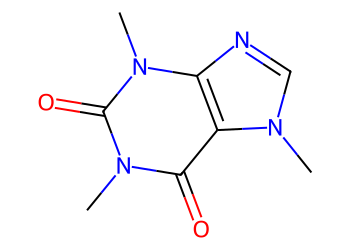

In [4]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')   # silence noisy parse warnings

caffeine = "CN1C=NC2=C1C(=O)N(C)C(=O)N2C"
mol = Chem.MolFromSmiles(caffeine)
print("Caffeine has", mol.GetNumAtoms(), "atoms and", mol.GetNumBonds(), "bonds")

for atom in list(mol.GetAtoms())[:5]:
    print(f"  atom {atom.GetIdx()}: {atom.GetSymbol():2s} "
          f"aromatic={atom.GetIsAromatic()} Hs={atom.GetTotalNumHs()} "
          f"degree={atom.GetDegree()}")
Draw.MolToImage(mol, size=(350,250))

## 3. From a molecule to `(X, edge_index)`

We need two arrays the network can consume:

- **`X`** — node features, shape `[num_atoms, num_features]`. Each atom becomes a vector: its element (one-hot), hybridization, charge, aromaticity, H-count, ring membership.
- **`edge_index`** — the bonds, shape `[2, num_edges]`. This **COO format** is what PyTorch Geometric uses too (Notebook 04), so we learn it now. Column `[i, j]` means "edge from atom i to atom j". Bonds are undirected, so we add **both** directions `i→j` and `j→i`.

Why COO and not the full N×N adjacency matrix? Molecules are **sparse** — a 50-atom molecule has ~50 bonds, not 2,500. Storing only the edges that exist is far cheaper, and it's the universal convention in GNN libraries.

In [5]:
ATOM_LIST = ['C','N','O','F','P','S','Cl','Br','I','B','Si','Na','K','other']
HYBRID    = ['SP','SP2','SP3','SP3D','SP3D2','other']

def onehot(x, choices):
    v = [0]*len(choices)
    v[choices.index(x) if x in choices else len(choices)-1] = 1
    return v

def atom_features(atom):
    return (onehot(atom.GetSymbol(), ATOM_LIST)
            + onehot(str(atom.GetHybridization()), HYBRID)
            + [atom.GetDegree()/4,            # scaled to ~[0,1]
               atom.GetFormalCharge(),
               int(atom.GetIsAromatic()),
               atom.GetTotalNumHs()/4,
               int(atom.IsInRing())])

FEAT_DIM = len(ATOM_LIST) + len(HYBRID) + 5
print("Each atom -> vector of length", FEAT_DIM)

def smiles_to_graph(smiles):
    """Return (X, edge_index) or None if the SMILES can't be parsed."""
    mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) else None
    if mol is None or mol.GetNumAtoms() == 0:
        return None
    X = np.array([atom_features(a) for a in mol.GetAtoms()], dtype=np.float32)
    src, dst = [], []
    for b in mol.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
        src += [i, j]; dst += [j, i]                 # both directions
    edge_index = (np.array([src, dst], dtype=np.int64)
                  if src else np.zeros((2,0), dtype=np.int64))
    return X, edge_index

Each atom -> vector of length 25


In [6]:
X, edge_index = smiles_to_graph("CCO")   # ethanol: C-C-O
print("Ethanol feature matrix X, shape", X.shape, "(3 atoms x 25 features)")
print(X)
print("\nedge_index, shape", edge_index.shape)
print(edge_index)
print("\nRead the columns: C0-C1, C1-C0, C1-O2, O2-C1  -> 2 bonds, 4 directed edges")

Ethanol feature matrix X, shape (3, 25) (3 atoms x 25 features)
[[1.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   1.   0.   0.   0.   0.25 0.   0.   0.75 0.  ]
 [1.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   1.   0.   0.   0.   0.5  0.   0.   0.5  0.  ]
 [0.   0.   1.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   1.   0.   0.   0.   0.25 0.   0.   0.25 0.  ]]

edge_index, shape (2, 4)
[[0 1 1 2]
 [1 0 2 1]]

Read the columns: C0-C1, C1-C0, C1-O2, O2-C1  -> 2 bonds, 4 directed edges


## 4. The BBBP dataset

**Blood–brain barrier penetration.** The BBB is a layer of cells that keeps most substances out of the brain. For a neurological drug (say, an antidepressant) penetration is *required*; for a drug acting elsewhere it's often an unwanted side effect. Predicting it early, from structure alone, saves enormous lab cost.

**BBBP** (MoleculeNet) gives ~2,000 molecules, each labelled `p_np`:
- `1` → penetrates the barrier
- `0` → does not

This is a **graph classification** task: one label per *whole graph*. We'll download the dataset and look at it.

In [7]:
import pandas as pd
url = "https://raw.githubusercontent.com/GLambard/Molecules_Dataset_Collection/master/latest/BBBP.csv"
df = pd.read_csv(url)
print("rows:", len(df), "| columns:", list(df.columns))
df[['name','p_np','smiles']].head()

rows: 2050 | columns: ['Unnamed: 0', 'num', 'name', 'p_np', 'smiles']


,name,p_np,smiles
0,Propanolol,1,CC(C)NCC(O)COC1:C:C:C:C2:C:C:C:C:C:1:2.[Cl]
1,Terbutylchlorambucil,1,CC(C)(C)OC(=O)CCCC1:C:C:C(N(CCCl)CCCl):C:C:1
2,40730,1,CC1COC2:C(N3CCN(C)CC3):C(F):C:C3:C(=O):C(C(=O)...
3,24,1,CC(=O)NCCCOC1:C:C:C:C(CN2CCCCC2):C:1
4,cloxacillin,1,CC1:O:N:C(C2:C:C:C:C:C:2Cl):C:1C(=O)N[C@@H]1C(...


In [8]:
pos = df['p_np'].mean()
print(f"Penetrates (label 1): {pos:.1%}   Does not (label 0): {1-pos:.1%}")
print("-> classes are IMBALANCED (~76% positive). We'll judge models with ROC-AUC,")
print("   which handles imbalance better than plain accuracy (Notebook 03).")

# Sanity-check: how many SMILES actually parse?
ok = sum(smiles_to_graph(s) is not None for s in df['smiles'])
print(f"\n{ok}/{len(df)} molecules parse cleanly ({len(df)-ok} malformed SMILES — a known BBBP quirk).")

Penetrates (label 1): 76.4%   Does not (label 0): 23.6%
-> classes are IMBALANCED (~76% positive). We'll judge models with ROC-AUC,
   which handles imbalance better than plain accuracy (Notebook 03).



2039/2050 molecules parse cleanly (11 malformed SMILES — a known BBBP quirk).


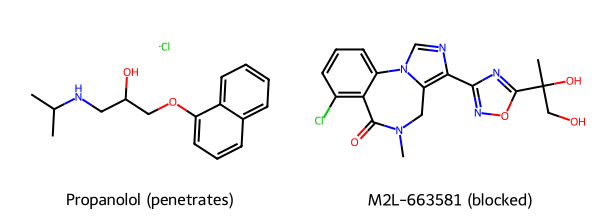

In [9]:
# Visualise a penetrating vs non-penetrating molecule.
from rdkit.Chem import Draw
ex_pos = df[df.p_np==1].iloc[0]
ex_neg = df[df.p_np==0].iloc[0]
mols  = [Chem.MolFromSmiles(ex_pos.smiles), Chem.MolFromSmiles(ex_neg.smiles)]
Draw.MolsToGridImage(mols, legends=[f"{ex_pos['name']} (penetrates)",
                                    f"{ex_neg['name']} (blocked)"],
                     molsPerRow=2, subImgSize=(300,220))

## Recap

- A graph = **nodes + edges**; a molecule = **atoms + bonds**.
- The core GNN move is **aggregating neighbour features** — and `A @ X` already does a crude version.
- We convert any molecule to **`X`** (node features) and **`edge_index`** (COO bonds) with `smiles_to_graph`.
- **BBBP** is a graph-classification benchmark: one 0/1 label per molecule, class-imbalanced.

**Next — Notebook 02:** why `A @ X` alone is unstable, how the **normalized adjacency** fixes it, and building a real **GCN layer** by hand.